---

## 1장 2강 과제 평가 문항 기반 독립 과제

### 문제. 유입 경로별 고객사 이탈률 비교하기

#### 문제 설명

Ravenstack 마케팅팀은 고객사가 유입된 경로에 따라 이탈 수준이 다른지 확인하려고 합니다. 유입 경로별 고객사 수와 이탈률을 비교하여 우선 점검할 유입 경로를 찾으세요.

> 이 과제는 필수 2에서 수행한 그룹별 지표 집계와 해석을 새로운 컬럼에 동일하게 적용하는 문제입니다.

#### 요구사항

1. `accounts`를 `referral_source`별로 그룹화하세요.
2. 다음 값을 집계하여 `source_metrics`를 만드세요.
   - 전체 고객사 수
   - 이탈 고객사 수
   - 고객사 이탈률
3. 고객사 이탈률이 높은 순서로 정렬하세요.
4. 이탈률은 소수점 둘째 자리의 백분율로 출력하세요.
5. 이탈률이 가장 높은 유입 경로를 찾으세요.
6. 해당 유입 경로를 우선 점검 대상으로 정하고, 확인할 개선 방향을 한 가지 제안하세요.
7. 유입 경로별 이탈률을 좋은 지표의 세 조건으로 평가하세요.
   - 행동 가능성
   - 비교 가능성
   - 이해 용이성

#### 해석 질문

**Q1.** 고객사 이탈률이 가장 높은 유입 경로는 무엇인가요?  
**Q2.** 유입 경로별 이탈률은 마케팅팀의 행동으로 어떻게 연결할 수 있나요?  
**Q3.** 유입 경로별 이탈률은 좋은 지표의 세 조건을 충족하나요?
**Q4.** KPI·보조 지표·허무 지표는 어떻게 다른가요? 고객사 이탈을 줄이려는 목적에서 각각의 지표 예시와 선정 이유를 제시하세요. 허무 지표는 어떤 맥락에서 성과 판단에 도움이 되지 않는지도 설명하세요.

#### 제출 결과

- `source_metrics` 집계 코드와 결과
- 우선 점검할 유입 경로
- 개선 방향
- 좋은 지표의 조건 평가
- Q1~Q4 답변

### 실습 준비

In [42]:
import pandas as pd

accounts = pd.read_csv('ravenstack_accounts.csv')
subscriptions = pd.read_csv('ravenstack_subscriptions.csv')
subscriptions['start_date'] = pd.to_datetime(subscriptions['start_date'])
subscriptions['end_date'] = pd.to_datetime(subscriptions['end_date'])

In [43]:
# 필수 2 코드를 작성하세요.
subscriptions["is_active_paid"] = (
    subscriptions["end_date"].isna()
    & (subscriptions["is_trial"] == False))

plan_metrics = subscriptions.groupby("plan_tier").agg(
    total_subscriptions=("subscription_id", "nunique"),
    churned_subscriptions=("churn_flag", "sum"),
    churn_rate=("churn_flag", "mean"),
    active_paid_subscriptions=("is_active_paid", "sum"))

active_mrr_by_plan = (
    subscriptions.loc[subscriptions["is_active_paid"]]
    .groupby("plan_tier")["mrr_amount"]
    .sum()
)
plan_metrics["active_mrr"] = active_mrr_by_plan

print(plan_metrics.to_string(formatters={
    "churn_rate": lambda x: f"{x:.2%}",
    "active_mrr": lambda x: f"${x:,.0f}"
}))

highest_mrr_plan = plan_metrics["active_mrr"].idxmax()
highest_churn_plan = plan_metrics["churn_rate"].idxmax()

print(f"현재 유료 구독 MRR이 가장 큰 요금제: {highest_mrr_plan}")
print(f"구독 이탈률이 가장 높은 요금제: {highest_churn_plan}")
print("우선 점검 대상: Enterprise")
print("개선 방향: Enterprise 이탈 고객의 이유와 사용 패턴을 확인합니다.")

            total_subscriptions  churned_subscriptions churn_rate  active_paid_subscriptions active_mrr
plan_tier                                                                                              
Basic                      1602                    152      9.49%                       1228   $687,914
Enterprise                 1723                    172      9.98%                       1304 $7,546,876
Pro                        1675                    162      9.67%                       1282 $1,924,818
현재 유료 구독 MRR이 가장 큰 요금제: Enterprise
구독 이탈률이 가장 높은 요금제: Enterprise
우선 점검 대상: Enterprise
개선 방향: Enterprise 이탈 고객의 이유와 사용 패턴을 확인합니다.


In [44]:
# 과제 코드를 작성하세요.
source_metrics = accounts.groupby('referral_source').agg(
    total_accounts = ('account_id', 'count'),
    churned_accounts = ('churn_flag', 'sum')
)
source_metrics['churn_rate'] = source_metrics['churned_accounts'] / source_metrics['total_accounts']

source_metrics = source_metrics.sort_values('churn_rate', ascending=False)

output = source_metrics.copy()
output['churn_rate'] = (output['churn_rate'] * 100).map('{:.2f}%'.format)
print(output)

top_source = source_metrics.index[0]
print(f"고객사 이탈률이 가장 높은 유입 경로: {top_source}")
print(f"우선 점검 대상: {top_source}")
print(f"개선 방향: {top_source} 경로로 유입된 고객사의 온보딩 과정과 초기 사용 패턴을 확인합니다.")

                 total_accounts  churned_accounts churn_rate
referral_source                                             
event                        96                29     30.21%
other                       103                25     24.27%
ads                          98                23     23.47%
organic                     114                20     17.54%
partner                      89                13     14.61%
고객사 이탈률이 가장 높은 유입 경로: event
우선 점검 대상: event
개선 방향: event 경로로 유입된 고객사의 온보딩 과정과 초기 사용 패턴을 확인합니다.


### 과제 답변 작성란

- **Q1.** 고객사 이탈률이 가장 높은 유입 경로는 무엇인가요?  
    - event가 가장 이탈률이 높은 유입 경로이다. 
- **Q2.** 유입 경로별 이탈률은 마케팅팀의 행동으로 어떻게 연결할 수 있나요?  
    - event 유입 고객사의 이탈률이 상대적으로 높게 나타났으므로 우선 점검 대상으로 볼 수 있다. 마케팅팀은 해당 경로로 유입된 고객사 초기 사용 패턴, 요금제 구성, 이탈 사유 등을 추가로 확인하고, 확인된 원인에 따라 타깃팅이나 온보딩 방식을 개선할 수 있다.
- **Q3.** 유입 경로별 이탈률은 좋은 지표의 세 조건을 충족하나요?
    - 행동 가능성: 충족. 유입 경로는 마케팅팀이 직접 조정할 수 있는 영역이라 바로 행동으로 연결될 수 있다. 다만 이탈률만으로는 이탈의 원인을 알 수 없으므로 사용 패턴 등 추가분석이 필요하다.
    - 비교 가능성: 충족. 절대적인 수치가 아닌 비율이기 때문에 경로간 비교가 가능하다. 다만 표본의 수가 적기 때문에 몇 건의 이탈만으로도 비율이 변할 수 있음은 유의해야 한다.
    - 이해 용이성: 충족. 비전문가도쉽게 이해할 수 있고 팀 간에 공유도 용이하다.
- **Q4.** KPI·보조 지표·허무 지표는 어떻게 다른가요? 고객사 이탈을 줄이려는 목적에서 각각의 지표 예시와 선정 이유를 제시하세요. 허무 지표는 어떤 맥락에서 성과 판단에 도움이 되지 않는지도 설명하세요.
    - KPI: 핵심 목표의 달성 여부를 직접 판단하는 지표
        - 예시로는 고객사 이탈률이 있다. 회사의 목표는 구독을 안정적으로 유지하며 매출을 늘리는 것이므로, 고객사의 이탈률이 이러한 목표 달성을 가장 직접적으로 보여준다.
    - 보조 지표: KPI가 왜 움직였는지 원인을 설명하고 행동 지점을 찾게 해주는 지표
        - 예시로는 유입 경로별 이탈률, 요금제별 이탈률 등이 있다. 전체 이탈률이 증가했을 때 어떤 구간에서 문제가 발생했는지 확인할 수 있어 KPI 개선을 위한 구체적인 행동으로 이어질 수 있다.
    - 허무 지표: 숫자는 좋아보이지만 목표 달성과 직접 연결되지 않아 의사결정에 도움이 되지 않는 지표
        - 예시로는 가입 수가 있다. 가입 수는 이탈 수와 무관하게 계속 증가하기 때문에 이탈과 관계 없이 성과가 좋아보이게 만든다. 이처럼 가입 수는 고객 유지라는 맥락에서는 성과 판단을 오히려 왜곡할 수 있다.


---

## 2장 1강 과제. 평가 문항 기반 독립 과제

### 문제. 결제 주기별 Activation 지표 비교하기

#### 문제 설명

프로덕트팀은 2024년 12월 제품 활성률이 월간 결제 구독과 연간 결제 구독에서 다르게 나타나는지 확인하려고 합니다.

> 이 과제는 필수 2의 요금제별 세그멘테이션을 `billing_frequency`에 동일하게 적용하는 문제입니다.

#### 요구사항

1. 필수 2에서 만든 `eligible_dec`과 `is_product_active`를 사용하세요.
2. `billing_frequency`별로 다음 값을 집계하여 `billing_activation`을 만드세요.
   - 이용 가능 유료 구독 수
   - 제품 활성 유료 구독 수
   - 제품 활성률
3. 제품 활성률이 낮은 순서로 정렬하고 백분율로 출력하세요.
4. 제품 활성률이 더 낮은 결제 주기를 찾으세요.
5. 해당 그룹을 우선 점검 대상으로 정하고 추가로 확인할 내용을 한 가지 제안하세요.
6. 이 분석의 AARRR 단계와 분석 기법을 설명하세요.

#### 해석 질문

**Q1.** 제품 활성률이 더 낮은 결제 주기는 무엇인가요?  
**Q2.** 이 분석은 어떤 AARRR 단계와 분석 기법에 해당하나요?  
**Q3.** 두 그룹의 제품 활성률 차이만으로 결제 주기가 낮은 활성의 원인이라고 결론 내릴 수 있나요?

**Q4.** 퍼널 분석·코호트 리텐션 분석·세그멘테이션을 표로 정리하세요. 각 분석의 계산 또는 분류 원리, 해결하려는 분석 질문, 관련 AARRR 단계를 설명하세요. 전환율·이탈률의 분모, 코호트의 시작 기준과 경과 기간, 세그먼트 분류 기준을 포함하세요.

#### 제출 결과

- `billing_activation` 집계 코드와 결과
- 우선 점검할 결제 주기
- 추가 확인 내용
- AARRR 단계와 분석 기법
- Q1~Q4 답변

### 실습 준비 코드

In [45]:
import pandas as pd

accounts = pd.read_csv("ravenstack_accounts.csv")
subscriptions = pd.read_csv("ravenstack_subscriptions.csv")
feature_usage = pd.read_csv("ravenstack_feature_usage.csv")

accounts['signup_date'] = pd.to_datetime(accounts['signup_date'])
subscriptions["start_date"] = pd.to_datetime(subscriptions['start_date'])
subscriptions['end_date'] = pd.to_datetime(subscriptions['end_date'])
feature_usage['usage_date'] = pd.to_datetime(feature_usage['usage_date'])

In [46]:
# 필수 2 코드를 작성하세요.
month_start = pd.Timestamp("2024-12-01")
month_end = pd.Timestamp("2024-12-31")

eligible_dec = subscriptions.loc[
    (subscriptions["is_trial"] == False)
    & (subscriptions["start_date"] <= month_end)
    & (
        subscriptions["end_date"].isna()
        | (subscriptions["end_date"] >= month_start)
    )
].copy()

active_subscription_ids = set(
    feature_usage.loc[
        (feature_usage["usage_date"] >= month_start)
        & (feature_usage["usage_date"] <= month_end)
        & (feature_usage["usage_count"] > 0),
        "subscription_id"
    ]
)

eligible_dec["is_product_active"] = eligible_dec["subscription_id"].isin(
    active_subscription_ids
)


In [47]:
# 과제 코드를 작성하세요.
billing_activation = eligible_dec.groupby('billing_frequency').agg(
    eligible_paid_subscriptions = ('subscription_id', 'nunique'),
    active_paid_subscriptions = ('is_product_active', 'sum'),
    activation_rate = ('is_product_active', 'mean')
)

billing_activation = billing_activation.sort_values('activation_rate')
print(billing_activation.to_string(formatters={'activation_rate': lambda x:f'{x:.2%}'}))

lowest_billing = billing_activation["activation_rate"].idxmin()
lowest_rate = billing_activation.loc[lowest_billing, "activation_rate"]
print(f"\n제품 활성률이 더 낮은 결제 주기: {lowest_billing}")
print(f"해당 결제 주기의 제품 활성률: {lowest_rate:.2%}")
print(f"우선 점검 대상: {lowest_billing}")
print(f"추가 확인 내용: {lowest_billing} 구독의 요금제 구성과 12월 이전 기능 사용 추이를 확인합니다.")
print("AARRR 단계: Activation")
print("분석 기법: 세그멘테이션 분석")

                   eligible_paid_subscriptions  active_paid_subscriptions activation_rate
billing_frequency                                                                        
annual                                    1968                        385          19.56%
monthly                                   2013                        403          20.02%

제품 활성률이 더 낮은 결제 주기: annual
해당 결제 주기의 제품 활성률: 19.56%
우선 점검 대상: annual
추가 확인 내용: annual 구독의 요금제 구성과 12월 이전 기능 사용 추이를 확인합니다.
AARRR 단계: Activation
분석 기법: 세그멘테이션 분석


### 과제 답변 작성란

- **Q1.** 제품 활성률이 더 낮은 결제 주기는 무엇인가요?  
    - annual, 19,56%로 monthly(20.02%)보다 낮은 제품 활성률을 보였다.
- **Q2.** 이 분석은 어떤 AARRR 단계와 분석 기법에 해당하나요?  
    - Activation 단계, 유료 구독자가 12월에 제품을 실제로 사용했는지를 확인했다.
    - 세그멘테이션 분석을 사용, 결제 주기별로 구독을 나누어 제품 활성률 차이를 비교했다.
- **Q3.** 두 그룹의 제품 활성률 차이만으로 결제 주기가 낮은 활성의 원인이라고 결론 내릴 수 있나요?
    - 어렵다. 세그멘테이션은 그룹 간 차이만 보여줄 뿐, 결제 주기가 원인이라는 것은 보여주지 않는다.
- **Q4.** 퍼널 분석·코호트 리텐션 분석·세그멘테이션을 표로 정리하세요. 각 분석의 계산 또는 분류 원리, 해결하려는 분석 질문, 관련 AARRR 단계를 설명하세요. 전환율·이탈률의 분모, 코호트의 시작 기준과 경과 기간, 세그먼트 분류 기준을 포함하세요.

| 구분 | 계산 또는 분류 원리 | 분석 질문 | AARRR 단계 |
| --- | --- | --- | --- |
| 퍼널 분석 | 단계별 전환율 = 다음 단계 도달 수 / 이전 단계 도달 수, 이탈률의 분모도 이전 단계 도달 수 | 어느 단계에서 가장 많이 이탈하는가? | Aquisition, Activation, Revenue |
| 코호트 리텐션 분석 | 가입일 월 기준으로 코호트를 묶고, 경과기간 별 활동 수 / 코호트 최초 인원 | 같은 시기에 시작한 고객이 시간이 지나도 계속 사용하는가? | Retention |
| 세그멘테이션 | 요금제, 결제 주기, 유입 경로 등 속성으로 그룹을 나누어 같은 지표를 비교 | 어떤 그룹의 지표가 낮아 우선 점검해야 하는가? | 모든 단계에 적용 가능 |


---

## 2장 2강 과제. 평가 문항 기반 독립 과제

### 문제. 결제 주기별 퍼널 비교하기

#### 문제 설명

월간 결제 구독과 연간 결제 구독의 퍼널을 비교하여 상대적으로 전환율이 낮은 그룹과 구간을 찾으세요.

> 이 과제는 필수 2에서 만든 함수와 분석 절차를 `billing_frequency`에 동일하게 적용하는 문제입니다.

#### 요구사항

1. `calculate_segment_funnel()`을 사용하여 `monthly`, `annual`의 퍼널을 계산하세요.
2. 두 결과를 결합하여 `billing_funnel`을 만드세요.
3. 첫 단계를 제외한 구간 전환율을 결제 주기별 막대그래프로 시각화하세요.
4. 모든 결제 주기와 구간의 조합 중 전환율이 가장 낮은 조합을 찾으세요.
5. 해당 그룹과 구간에 대한 개선 가설을 한 가지 제안하세요.
6. 퍼널 결과만으로 원인을 확정할 수 없는 이유와 추가 확인할 데이터를 설명하세요.

#### 해석 질문

**Q1.** 전환율이 가장 낮은 결제 주기와 구간의 조합은 무엇인가요?  
**Q2.** 해당 구간의 전환율과 이탈률은 얼마인가요?  
**Q3.** 이 결과만으로 결제 주기가 이탈의 원인이라고 말할 수 있나요?

#### 제출 결과

- `billing_funnel` 결과
- 결제 주기별 전환율 그래프
- 우선 점검 대상과 개선 가설
- 분석의 한계와 추가 확인 데이터
- Q1~Q3 답변

실습 준비

In [48]:
import pandas as pd
import matplotlib.pyplot as plt

subscriptions = pd.read_csv("ravenstack_subscriptions.csv")
feature_usage = pd.read_csv("ravenstack_feature_usage.csv")

subscriptions["start_date"] = pd.to_datetime(subscriptions["start_date"])
subscriptions["end_date"] = pd.to_datetime(subscriptions["end_date"])
feature_usage["usage_date"] = pd.to_datetime(feature_usage["usage_date"])

In [49]:
usage_ids = set(feature_usage.loc[feature_usage["usage_count"] > 0, "subscription_id"])
non_trial_ids = set(subscriptions.loc[subscriptions["is_trial"] == False, "subscription_id"])
not_ended_ids = set(subscriptions.loc[subscriptions["end_date"].isna(), "subscription_id"])

def calculate_segment_funnel(segment_ids, segment_name):
    segment_started = set(segment_ids)
    segment_used = segment_started & usage_ids
    segment_paid = segment_used & non_trial_ids
    segment_retained = segment_paid & not_ended_ids

    result = pd.DataFrame({
        "segment": segment_name,
        "stage": ["구독 시작", "기능 사용", "유료 구독", "현재 유료 유지"],
        "subscriptions": [
            len(segment_started), len(segment_used),
            len(segment_paid), len(segment_retained)]})
    result["conversion_rate"] = result["subscriptions"] / result["subscriptions"].shift(1)
    result.loc[0, "conversion_rate"] = 1.0
    result["dropoff_rate"] = 1 - result["conversion_rate"]
    return result

segment    stage subscriptions conversion_rate dropoff_rate
monthly    구독 시작         2,539         100.00%        0.00%
monthly    기능 사용         2,520          99.25%        0.75%
monthly    유료 구독         2,120          84.13%       15.87%
monthly 현재 유료 유지         1,930          91.04%        8.96%
 annual    구독 시작         2,461         100.00%        0.00%
 annual    기능 사용         2,447          99.43%        0.57%
 annual    유료 구독         2,073          84.72%       15.28%
 annual 현재 유료 유지         1,858          89.63%       10.37%


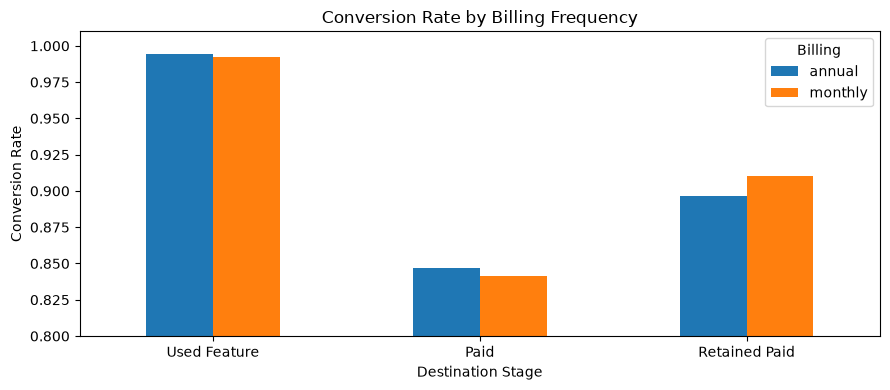


가장 낮은 조합: monthly - 유료 구독 구간
전환율: 84.13%
이탈률: 15.87%
개선 가설: monthly 구독에서는 체험 종료 후 유료 전환 과정에서 이탈이 발생하며, 체험 종료 전 유료 기능과 혜택을 안내하면 구독 전환율이 개선될 것이다.


In [50]:
# 과제 코드를 작성하세요
billing_results = []
for billing in ["monthly", "annual"]:
    billing_ids = subscriptions.loc[
        subscriptions["billing_frequency"] == billing, "subscription_id"]
    billing_results.append(calculate_segment_funnel(billing_ids, billing))

billing_funnel = pd.concat(billing_results, ignore_index=True)
print(billing_funnel.to_string(index=False, formatters={
    "subscriptions": lambda x: f"{x:,.0f}",
    "conversion_rate": lambda x: f"{x:.2%}",
    "dropoff_rate": lambda x: f"{x:.2%}"}))

billing_plot = (
    billing_funnel.loc[billing_funnel["stage"] != "구독 시작"]
    .pivot(index="stage", columns="segment", values="conversion_rate")
    .reindex(["기능 사용", "유료 구독", "현재 유료 유지"]))
billing_plot.index = ["Used Feature", "Paid", "Retained Paid"]

ax = billing_plot.plot(kind="bar", figsize=(9, 4), ylim=(0.80, 1.01))
ax.set_title("Conversion Rate by Billing Frequency")
ax.set_xlabel("Destination Stage")
ax.set_ylabel("Conversion Rate")
ax.legend(title="Billing")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

lowest_billing_row = (billing_funnel.loc[billing_funnel["stage"] != "구독 시작"]
                      .sort_values("conversion_rate").iloc[0])
print(f"\n가장 낮은 조합: {lowest_billing_row['segment']} - {lowest_billing_row['stage']} 구간")
print(f"전환율: {lowest_billing_row['conversion_rate']:.2%}")
print(f"이탈률: {lowest_billing_row['dropoff_rate']:.2%}")
print(f"개선 가설: {lowest_billing_row['segment']} 구독에서는 체험 종료 후 유료 전환 과정에서 이탈이 발생하며, 체험 종료 전 유료 기능과 혜택을 안내하면 구독 전환율이 개선될 것이다.")

### 과제 답변 작성란

- **Q1.** 전환율이 가장 낮은 결제 주기와 구간의 조합은 무엇인가요?  
    - monthly 결제 주기의 유료 구독 구간
- **Q2.** 해당 구간의 전환율과 이탈률은 얼마인가요?  
    - 전환율은 84.13%, 이탈률은 15.87%
- **Q3.** 이 결과만으로 결제 주기가 이탈의 원인이라고 말할 수 있나요?
    - 없다. 퍼널은 어느 그룹, 어느 구간에서 구독이 줄었는지만 보여주고 원인은 알려주지 않는다.
    - 요금제 구성 차이나 체험 기간 등 다른 요인일 수 있어, 요금제와 교차 비교, 체험 종료 데이터, 이탈 사유, 고객 문의 데이터를 추가로 확인해야 한다.

---

## 2장 3강 과제. 평가 문항 기반 독립 과제

### 문제. 코호트·결제 주기별 Month 1~3 리텐션 비교하기

#### 문제 설명

2024년 1월부터 6월까지의 첫 유효 기능 사용 월 코호트를 대상으로, 월간 결제 구독과 연간 결제 구독의 Month 1~3 리텐션을 비교하세요. 시간이 지나면서 유지율이 어떻게 변하는지 확인하고 개선 방향을 제안하세요.

> 필수 1의 월별 코호트 분석과 필수 2의 세그먼트별 비교 절차를 활용하는 문제입니다.

#### 요구사항

1. 구독별 cohort_month, billing_frequency를 한 행으로 정리하세요.
2. 2024년 1월~6월 코호트만 선택하고, 각 코호트의 Month 3까지 관찰 가능한지 확인하세요. 아직 관찰하지 못한 월은 리텐션을 0으로 처리하지 마세요.
3. 코호트·결제 주기별 최초 구독 수와 Month 1·2·3 각각의 고유 재사용 구독 수를 계산하세요. 같은 구독이 같은 달에 여러 번 사용해도 한 번만 세세요.
4. 다음 식으로 billing_retention을 만드세요.
- 리텐션 = 해당 경과 월의 고유 재사용 구독 수 ÷ 해당 코호트·결제 주기의 최초 구독 수
- Month 1~3 모두 같은 최초 구독 수를 분모로 사용하세요.
- 이전 달에 사용하지 않았어도 해당 달에 다시 사용했다면 포함하세요.
5. 행은 코호트·결제 주기, 열은 Month 1~3인 리텐션 표를 만들고 백분율로 출력하세요.
6. 코호트별로 월간·연간 결제 구독의 Month 1~3 리텐션을 비교하는 선그래프를 그리세요.
7. 각 코호트에서 두 결제 주기의 Month 1 리텐션 차이와, 각 결제 주기의 Month 1→2 및 Month 2→3 변화폭을 %p로 계산하세요. 감소·유지·회복 등의 패턴을 실제 결과에 맞게 해석하세요.
8. 우선 점검할 코호트·결제 주기 조합을 선택하고, 수치 근거·가능한 원인 가설·개선 방향·추가 확인 데이터를 제안하세요. 원인 가설을 확인된 사실처럼 단정하지 마세요.

#### 해석 질문

**Q1.** 각 코호트에서 Month 1 리텐션이 더 낮은 결제 주기는 무엇이며, 두 결제 주기의 차이는 몇 %p인가요?

**Q2.** 코호트·결제 주기별 Month 1→2 및 Month 2→3 변화폭은 몇 %p이며, 어떤 유지 패턴이 나타나나요?

**Q3.** 우선 점검할 코호트·결제 주기는 무엇인가요? 수치 근거와 가능한 원인 가설, 개선 방향을 설명하세요.

**Q4.** 이 결과만으로 결제 주기가 낮은 리텐션의 원인이라고 판단할 수 있나요? 추가로 어떤 데이터를 확인해야 하나요?

#### 제출 결과

- 코호트·결제 주기별 최초 구독 수와 Month 1~3 고유 재사용 구독 수
- billing_retention 표와 리텐션 선그래프
- 결제 주기 간 차이와 경과 월별 변화폭(%p)
- 시간 경과에 따른 유지 패턴 해석
- 우선 점검 대상·원인 가설·개선 방향·추가 확인 데이터
- Q1~Q4 답변

### 실습 준비

In [51]:
import pandas as pd
import matplotlib.pyplot as plt

subscriptions = pd.read_csv("ravenstack_subscriptions.csv")
feature_usage = pd.read_csv("ravenstack_feature_usage.csv")

subscriptions["start_date"] = pd.to_datetime(subscriptions["start_date"])
subscriptions["end_date"] = pd.to_datetime(subscriptions["end_date"])
feature_usage["usage_date"] = pd.to_datetime(feature_usage["usage_date"])

usage_with_sub = feature_usage.merge(
    subscriptions[[
        "subscription_id", "start_date", "end_date",
        "plan_tier", "billing_frequency"]], on="subscription_id", how="inner")

before_start_count = (usage_with_sub["usage_date"] < usage_with_sub["start_date"]).sum()
after_end_count = (usage_with_sub["end_date"].notna() & (usage_with_sub["usage_date"] > usage_with_sub["end_date"])).sum()

valid_usage = usage_with_sub.loc[(usage_with_sub["usage_count"] > 0) & (usage_with_sub["usage_date"] >= usage_with_sub["start_date"])
    & (usage_with_sub["end_date"].isna() | (usage_with_sub["usage_date"] <= usage_with_sub["end_date"]))].copy()

print(f"\n구독 시작 전 사용 기록: {before_start_count:,}건")
print(f"구독 종료 후 사용 기록: {after_end_count:,}건")
print(f"유효 기능 사용 기록: {len(valid_usage):,}건")
print(f"유효 기능 사용 구독 수: {valid_usage['subscription_id'].nunique():,}개")


구독 시작 전 사용 기록: 19,142건
구독 종료 후 사용 기록: 290건
유효 기능 사용 기록: 5,568건
유효 기능 사용 구독 수: 2,651개


In [52]:
# 필수 1 코드를 작성하세요.
valid_usage["activity_month"] = valid_usage["usage_date"].dt.to_period("M")

first_activity = (valid_usage.groupby("subscription_id")["activity_month"].min().rename("cohort_month"))
valid_usage = valid_usage.join(first_activity, on="subscription_id")

valid_usage["month_index"] = (valid_usage["activity_month"].astype("int64") - valid_usage["cohort_month"].astype("int64"))

데이터의 마지막 관찰 월: 2024-12
cohort_month  observable_months  month3_observable
     2024-01                 11               True
     2024-02                 10               True
     2024-03                  9               True
     2024-04                  8               True
     2024-05                  7               True
     2024-06                  6               True

[최초 구독 수와 Month 1~3 고유 재사용 구독 수]
month_index                     cohort_subscriptions   1   2   3
cohort_month billing_frequency                                  
2024-01      annual                               46   6   7  10
             monthly                              27   5   5   4
2024-02      annual                               39  10   5   4
             monthly                              50   9  10  10
2024-03      annual                               55  11  11  11
             monthly                              52  13  13  11
2024-04      annual                               49   8  13   8
 

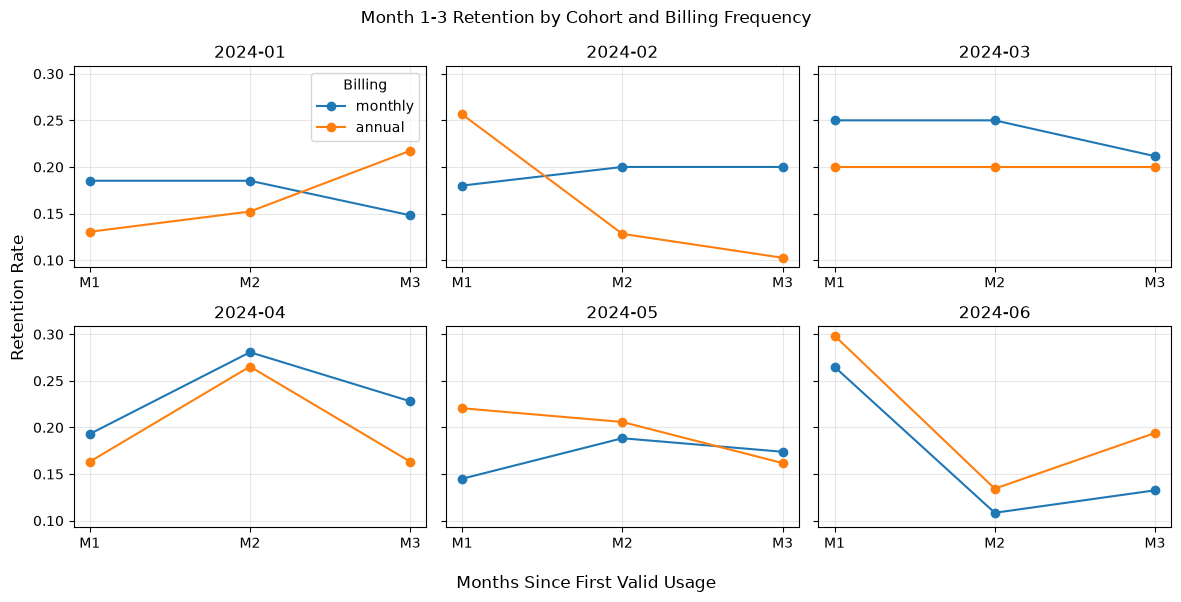


[코호트별 Month 1 리텐션 차이]
billing_frequency monthly annual annual_minus_monthly(%p) lower_billing
cohort_month                                                           
2024-01            18.52% 13.04%                  -5.48%p        annual
2024-02            18.00% 25.64%                  +7.64%p       monthly
2024-03            25.00% 20.00%                  -5.00%p        annual
2024-04            19.30% 16.33%                  -2.97%p        annual
2024-05            14.49% 22.06%                  +7.57%p       monthly
2024-06            26.51% 29.85%                  +3.34%p       monthly

[경과 월별 변화폭과 패턴]
                               M1→M2(%p) M2→M3(%p)  pattern
cohort_month billing_frequency                             
2024-01      annual              +2.17%p   +6.52%p  증가 → 증가
             monthly             +0.00%p   -3.70%p  유지 → 감소
2024-02      annual             -12.82%p   -2.56%p  감소 → 감소
             monthly             +2.00%p   +0.00%p  증가 → 유지
2024-03      annual     

In [53]:
# 과제 코드를 작성
# 1. 구독별 cohort_month, billing_frequency 한 행으로 정리
billing_base = (valid_usage[["subscription_id", "cohort_month", "billing_frequency"]]
                .drop_duplicates("subscription_id"))

# 2. 2024년 1~6월 코호트 선택 + Month 3까지 관찰 가능 여부 확인
billing_selected = billing_base.loc[
    (billing_base["cohort_month"] >= pd.Period("2024-01"))
    & (billing_base["cohort_month"] <= pd.Period("2024-06"))].copy()

last_month = valid_usage["activity_month"].max()
observability = pd.DataFrame({"cohort_month": sorted(billing_selected["cohort_month"].unique())})
observability["observable_months"] = observability["cohort_month"].apply(
    lambda c: last_month.ordinal - c.ordinal)
observability["month3_observable"] = observability["observable_months"] >= 3
print(f"데이터의 마지막 관찰 월: {last_month}")
print(observability.to_string(index=False))

# 3. 코호트·결제 주기별 최초 구독 수와 Month 1~3 고유 재사용 구독 수
billing_sizes = billing_selected.groupby(["cohort_month", "billing_frequency"])["subscription_id"].nunique()

returned = valid_usage.loc[
    valid_usage["subscription_id"].isin(billing_selected["subscription_id"])
    & valid_usage["month_index"].between(1, 3)]
returned_counts = (returned.groupby(["cohort_month", "billing_frequency", "month_index"])["subscription_id"]
                   .nunique().unstack(fill_value=0)
                   .reindex(columns=[1, 2, 3], fill_value=0)
                   .reindex(billing_sizes.index, fill_value=0))

count_table = returned_counts.copy()
count_table.insert(0, "cohort_subscriptions", billing_sizes)
print("\n[최초 구독 수와 Month 1~3 고유 재사용 구독 수]")
print(count_table.to_string())

# 4. billing_retention: 모든 경과 월에 같은 최초 구독 수를 분모로 사용
billing_retention = returned_counts.div(billing_sizes, axis=0)

# 아직 관찰하지 못한 월은 0이 아닌 NaN으로 처리
obs_map = observability.set_index("cohort_month")["observable_months"]
row_obs = billing_retention.index.get_level_values("cohort_month").map(obs_map)
for m in [1, 2, 3]:
    billing_retention.loc[row_obs < m, m] = np.nan

# 5. 백분율 표 출력
pct = lambda x: "관찰 불가" if pd.isna(x) else f"{x:.2%}"
print("\n[billing_retention]")
print(billing_retention.to_string(formatters={m: pct for m in [1, 2, 3]}))

# 6. 코호트별 월간·연간 Month 1~3 리텐션 선그래프
cohorts = billing_retention.index.get_level_values("cohort_month").unique()
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
for ax, cohort in zip(axes.flat, cohorts):
    for billing in ["monthly", "annual"]:
        if (cohort, billing) in billing_retention.index:
            ax.plot([1, 2, 3], billing_retention.loc[(cohort, billing), [1, 2, 3]].values,
                    marker="o", label=billing)
    ax.set_title(str(cohort))
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(["M1", "M2", "M3"])
    ax.grid(alpha=0.3)
axes.flat[0].legend(title="Billing")
fig.suptitle("Month 1-3 Retention by Cohort and Billing Frequency")
fig.supxlabel("Months Since First Valid Usage")
fig.supylabel("Retention Rate")
plt.tight_layout()
plt.show()

# 7-1. 코호트별 두 결제 주기의 Month 1 리텐션 차이(%p)
m1 = billing_retention[1].unstack("billing_frequency")
m1_gap = m1[["monthly", "annual"]].copy()
m1_gap["annual_minus_monthly(%p)"] = (m1["annual"] - m1["monthly"]) * 100
m1_gap["lower_billing"] = np.where(m1["annual"] < m1["monthly"], "annual", "monthly")
print("\n[코호트별 Month 1 리텐션 차이]")
print(m1_gap.to_string(formatters={
    "monthly": pct, "annual": pct, "annual_minus_monthly(%p)": lambda x: f"{x:+.2f}%p"}))

# 7-2. 결제 주기별 Month 1→2, Month 2→3 변화폭(%p)과 패턴 (±1%p 이내는 유지로 판단)
def label(diff):
    if pd.isna(diff):
        return "관찰 불가"
    return "유지" if abs(diff) < 1 else ("증가" if diff > 0 else "감소")

change = pd.DataFrame({
    "M1→M2(%p)": (billing_retention[2] - billing_retention[1]) * 100,
    "M2→M3(%p)": (billing_retention[3] - billing_retention[2]) * 100})
change["pattern"] = change.apply(
    lambda r: f"{label(r['M1→M2(%p)'])} → {label(r['M2→M3(%p)'])}", axis=1)
print("\n[경과 월별 변화폭과 패턴]")
print(change.to_string(formatters={
    "M1→M2(%p)": lambda x: f"{x:+.2f}%p", "M2→M3(%p)": lambda x: f"{x:+.2f}%p"}))

# 8. 우선 점검 대상: Month 3 리텐션이 가장 낮은 코호트·결제 주기 조합
priority = billing_retention[3].idxmin()
print(f"\n우선 점검 대상: {priority[0]} 코호트 - {priority[1]}")
print(f"Month 1~3 리텐션: " + ", ".join(pct(v) for v in billing_retention.loc[priority, [1, 2, 3]]))
print(f"Month 1→3 변화폭: {(billing_retention.loc[priority, 3] - billing_retention.loc[priority, 1]) * 100:+.2f}%p "
      f"(최초 구독 수 {billing_sizes.loc[priority]}개)")

### 과제 답변 작성란

- **Q1.** 각 코호트에서 Month 1 리텐션이 더 낮은 결제 주기는 무엇이며, 두 결제 주기의 차이는 몇 %p인가요?
    - 1월 annual(5.48%p), 2월 monthly(7.64%p), 3월 annual(5.00%p), 4월 annual(2.97%p), 5월 monthly(7.57%p), 6월 monthly(3.34%p)
    - 6개의 코호트 중 annual과 monthly가 각각 3번씩 더 낮아 어느 한 결제 주기가 일관되게 낮다고 보기가 어렵다.

- **Q2.** 코호트·결제 주기별 Month 1→2 및 Month 2→3 변화폭은 몇 %p이며, 어떤 유지 패턴이 나타나나요?
    - 변화폭은 표 참고, 코호트마다 패턴이 다르게 나타났다.
    - 2024-02 annual은 -12.82%p, -2.56%p로 유일하게 지속 감소했고, 2024-01 annual은 +2.17%p, +6.52%p로 지속 회복했다.
    - 2024-06은 두 결제주기 모두 Month 2에서 약 16%p 급감한 뒤 Month 3에 일부 회복했고, 2024-04는 두 결제 주기 모두 Month 2에 올랐다가 다시 감소했다.
    - 2024-03 annual은 Month 1~3 모두 20.00%로 유지되었다.

- **Q3.** 우선 점검할 코호트·결제 주기는 무엇인가요? 수치 근거와 가능한 원인 가설, 개선 방향을 설명하세요.
    - 2024-02 코호트의 annual, Month 1 리텐션은 25.64%로 높았지만 Month2 12.82%, Month 3 10.26%로 Month 1 대비 15.38%p 감소했다.
    - 같은 코호트의 Monthly(18.00% -> 20.00% -> 20.00%)는 유지되어, annual만 초기 사용 이후 빠르게 줄어든 점이 두드러진다.
    - 가설: annual 구독에서는 초기 사용 이후 지속적인 기능 사용을 유도하는 요인이 부족하거나, 제품을 반복적으로 사용할 필요성이 낮은 고객이 포함되어 있을 수 있다.
    - 개선 방향: 첫 사용 후 1~2개월 차에 활용 가이드나 재사용 알림을 보내 사용 습관이 자리 잡도록 유도한다. 단, 최초 구독 수가 39개로 작아 구독 1개가 약 2.6%p에 해당하므로, 몇 건의 차이로도 리텐션이 크게 흔들릴 수 있다.

- **Q4.** 이 결과만으로 결제 주기가 낮은 리텐션의 원인이라고 판단할 수 있나요? 추가로 어떤 데이터를 확인해야 하나요?
    - NO. 코호트마다 더 낮은 결제 주기가 달라 일관된 차이가 없고, 그룹별 구독 수도 적어 우연한 변동일 가능성이 있다.
    - 결제 주기와 요금제 교차 비교, 고객 문의, 이탈 사유 데이터 등을 추가로 확인해야 한다.

---

## 2장 4강 과제. 평가 문항 기반 독립 과제

### 문제. 첫 구독 요금제별 퍼널 비교와 개선 가설 제안하기

#### 문제 설명

첫 구독의 plan_tier별로 Acquisition → Activation → Retention → Revenue 단계의 계정 수와 전환율을 비교하세요. 이탈이 집중된 구간을 찾고, 개선 가설과 검증 방법을 제안하세요.

> 필수 문제의 단계 정의와 집계·전환율 계산·시각화 절차를 그대로 활용합니다. Referral은 관련 행동 기록이 없어 분석에서 제외합니다.

#### 요구사항

1. 원시 계정·구독·기능 사용 데이터를 연결하여 funnel_base와 단계 도달 여부를 만드는 코드를 제출물에 포함하세요. 필수 문제에서 작성한 코드를 재사용해도 됩니다.
2. 첫 구독의 plan_tier별로 Acquisition, Activation, Retention, Revenue의 고유 계정 수를 집계하세요. 각 단계에는 이전 단계에 도달한 계정만 포함하세요.
3. 요금제별로 다음 값을 계산하여 plan_funnel을 만드세요.
- 구간 전환율 = 현재 단계 계정 수 ÷ 이전 단계 계정 수 × 100
- 구간 이탈률 = 100 − 구간 전환율
- 구간 이탈 계정 수 = 이전 단계 계정 수 − 현재 단계 계정 수
- 첫 단계는 비교할 이전 단계가 없으므로 구간 지표를 빈 값으로 두세요. 이전 단계 계정 수가 0이면 전환율·이탈률을 계산 불가로 표시하세요.
4. 요금제별로 단계별 고유 계정 수를 가로 막대그래프로 시각화하고, 각 단계의 구간 전환율을 함께 표시하세요.
5. 첫 단계를 제외하고 전환율이 가장 낮은 요금제·구간 조합을 찾으세요. 해당 구간의 전환율·이탈률·이탈 계정 수를 근거로 이탈 집중 구간을 설명하세요.
6. 요금제별 최종 Revenue 도달률을 계산하여 plan_summary로 출력하세요. 가장 높은 요금제와 낮은 요금제의 차이를 %p로 계산하세요.
- 최종 Revenue 도달률 = Revenue 계정 수 ÷ Acquisition 계정 수 × 100
7. 우선 점검할 구간에 대해 “어떤 원인 때문에 이탈하며, 어떤 변경을 하면 전환율이 개선될 것이다”라는 개선 가설을 한 가지 작성하세요.
8. 가설을 확인하기 위한 추가 데이터 2가지와 검증 방법을 설명하세요. 어떤 대상을 비교하고 어떤 지표로 개선 여부를 판단할지 포함하세요. 실제 실험이나 통계 검정은 수행하지 않아도 됩니다.

#### 해석 질문

Q1. 전환율이 가장 낮은 요금제와 구간은 무엇이며, 전환율·이탈률·이탈 계정 수는 얼마인가요?

Q2. 최종 Revenue 도달률이 가장 높은 요금제와 낮은 요금제는 무엇이며, 차이는 몇 %p인가요?

Q3. 우선 점검할 구간에 대한 개선 가설은 무엇이며, 어떤 데이터와 방법으로 검증할 수 있나요?

Q4. 요금제별 차이만으로 요금제가 이탈의 원인이라고 결론 내릴 수 있나요?

#### 제출 결과

- 원시 데이터 연결 및 단계 도달 여부 구성 코드
- plan_funnel: 단계별 계정 수·전환율·이탈률·이탈 계정 수
- 요금제별 퍼널 그래프
- 이탈 집중 구간과 수치 근거
- plan_summary: 최종 Revenue 도달률과 최고·최저 차이
- 개선 가설·추가 확인 데이터 2가지·검증 방법
- Q1~Q4 답변

### 실습 준비

In [54]:
import pandas as pd
import matplotlib.pyplot as plt

accounts = pd.read_csv("ravenstack_accounts.csv")
subscriptions = pd.read_csv("ravenstack_subscriptions.csv")
feature_usage = pd.read_csv("ravenstack_feature_usage.csv")

accounts["signup_date"] = pd.to_datetime(accounts["signup_date"])
subscriptions["start_date"] = pd.to_datetime(subscriptions["start_date"])
subscriptions["end_date"] = pd.to_datetime(subscriptions["end_date"])
feature_usage["usage_date"] = pd.to_datetime(feature_usage["usage_date"])

first_subscription = (subscriptions.sort_values(["account_id", "start_date", "subscription_id"]).drop_duplicates("account_id")
    [["account_id", "subscription_id", "start_date", "end_date","plan_tier", "is_trial", "mrr_amount"]])

usage_with_first_sub = feature_usage.merge(
    first_subscription[[
        "account_id", "subscription_id", "start_date", "end_date"]], on="subscription_id", how="inner")

before_start = usage_with_first_sub["usage_date"] < usage_with_first_sub["start_date"]
after_end = (usage_with_first_sub["end_date"].notna()
    & (usage_with_first_sub["usage_date"] > usage_with_first_sub["end_date"]))

valid_usage = usage_with_first_sub.loc[
    (usage_with_first_sub["usage_count"] > 0) & ~before_start & ~after_end].copy()

observation_end = feature_usage["usage_date"].max()
observation_cutoff = observation_end - pd.Timedelta(days=30)

In [55]:
# 필수 1 코드를 작성하세요.
funnel_base = (
    accounts.loc[
        accounts["signup_date"] <= observation_cutoff,
        ["account_id", "signup_date", "industry"]
    ]
    .merge(first_subscription, on="account_id", how="left")
)

retained_account_ids = set(
    valid_usage.loc[
        valid_usage["usage_date"]
        >= valid_usage["start_date"] + pd.Timedelta(days=30),
        "account_id"
    ]
)

funnel_base["Acquisition"] = True
funnel_base["Activation"] = (
    (funnel_base["start_date"] >= funnel_base["signup_date"])
    & (funnel_base["start_date"] <= funnel_base["signup_date"] + pd.Timedelta(days=30))
)
funnel_base["Retention"] = (
    funnel_base["Activation"]
    & funnel_base["account_id"].isin(retained_account_ids)
)
funnel_base["Revenue"] = (
    funnel_base["Retention"]
    & funnel_base["is_trial"].eq(False)
    & (funnel_base["mrr_amount"] > 0)
)

funnel_stages = ["Acquisition", "Activation", "Retention", "Revenue"]


 plan_tier       stage  accounts conversion_pct dropoff_pct lost_accounts
     Basic Acquisition       161                                         
     Basic  Activation       101          62.7%       37.3%            60
     Basic   Retention        70          69.3%       30.7%            31
     Basic     Revenue        58          82.9%       17.1%            12
       Pro Acquisition       159                                         
       Pro  Activation       101          63.5%       36.5%            58
       Pro   Retention        66          65.3%       34.7%            35
       Pro     Revenue        59          89.4%       10.6%             7
Enterprise Acquisition       163                                         
Enterprise  Activation       119          73.0%       27.0%            44
Enterprise   Retention        71          59.7%       40.3%            48
Enterprise     Revenue        60          84.5%       15.5%            11


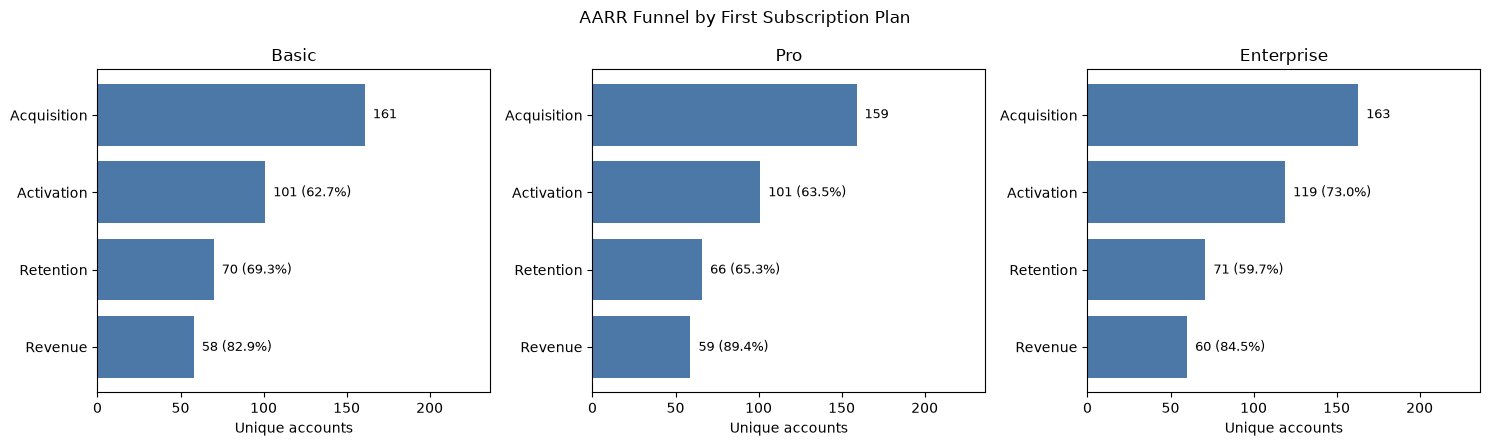


전환율이 가장 낮은 조합: Enterprise - Activation → Retention 구간
전환율: 59.7%, 이탈률: 40.3%, 이탈 계정 수: 48개

[plan_summary]
stage       Acquisition  Revenue revenue_reach_pct
plan_tier                                         
Pro                 159       59             37.1%
Enterprise          163       60             36.8%
Basic               161       58             36.0%

최종 Revenue 도달률 최고: Pro, 최저: Basic, 차이: 1.1%p


In [56]:
# 과제 코드를 작성하세요.
# 2. 요금제별 단계 도달 고유 계정 수 (각 단계는 이미 이전 단계 조건을 누적 적용함)
plans = ["Basic", "Pro", "Enterprise"]
plan_log = pd.concat(
    [funnel_base.loc[funnel_base[stage], ["account_id", "plan_tier"]].assign(stage=stage)
     for stage in funnel_stages], ignore_index=True)

plan_counts = (plan_log.groupby(["plan_tier", "stage"])["account_id"].nunique()
               .unstack("stage")
               .reindex(index=plans, columns=funnel_stages)
               .fillna(0).astype(int))

# 3. plan_funnel: 구간 전환율·이탈률·이탈 계정 수
rows = []
for plan in plans:
    for i, stage in enumerate(funnel_stages):
        current = plan_counts.loc[plan, stage]
        if i == 0:
            prev, conv, drop, lost = np.nan, np.nan, np.nan, np.nan
        else:
            prev = plan_counts.loc[plan, funnel_stages[i - 1]]
            lost = prev - current
            conv = current / prev * 100 if prev > 0 else np.nan
            drop = 100 - conv if prev > 0 else np.nan
        rows.append({"plan_tier": plan, "stage": stage, "accounts": current,
                     "prev_accounts": prev, "conversion_pct": conv,
                     "dropoff_pct": drop, "lost_accounts": lost})
plan_funnel = pd.DataFrame(rows)

# 출력용: 첫 단계는 빈 값, 이전 단계가 0이면 계산 불가
def fmt_rate(row, col):
    if row["stage"] == "Acquisition":
        return ""
    if row["prev_accounts"] == 0:
        return "계산 불가"
    return f"{row[col]:.1f}%"

plan_funnel_display = plan_funnel[["plan_tier", "stage", "accounts"]].copy()
plan_funnel_display["conversion_pct"] = plan_funnel.apply(lambda r: fmt_rate(r, "conversion_pct"), axis=1)
plan_funnel_display["dropoff_pct"] = plan_funnel.apply(lambda r: fmt_rate(r, "dropoff_pct"), axis=1)
plan_funnel_display["lost_accounts"] = plan_funnel["lost_accounts"].apply(
    lambda x: "" if pd.isna(x) else f"{int(x)}")
print(plan_funnel_display.to_string(index=False))

# 4. 요금제별 가로 막대 퍼널 그래프 + 구간 전환율 표시
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True)
for ax, plan in zip(axes, plans):
    data = plan_funnel.loc[plan_funnel["plan_tier"] == plan].iloc[::-1]
    ax.barh(data["stage"], data["accounts"], color="#4C78A8")
    for i, (_, row) in enumerate(data.iterrows()):
        label = f"  {int(row['accounts'])}"
        if row["stage"] != "Acquisition":
            label += " (계산 불가)" if row["prev_accounts"] == 0 else f" ({row['conversion_pct']:.1f}%)"
        ax.text(row["accounts"], i, label, va="center", fontsize=9)
    ax.set_title(plan)
    ax.set_xlabel("Unique accounts")
axes[0].set_xlim(0, plan_counts["Acquisition"].max() * 1.45)
fig.suptitle("AARR Funnel by First Subscription Plan")
plt.tight_layout()
plt.show()

# 5. 전환율이 가장 낮은 요금제·구간 조합
valid_rows = plan_funnel.loc[(plan_funnel["stage"] != "Acquisition") & plan_funnel["conversion_pct"].notna()]
lowest = valid_rows.loc[valid_rows["conversion_pct"].idxmin()]
prev_stage = funnel_stages[funnel_stages.index(lowest["stage"]) - 1]
print(f"\n전환율이 가장 낮은 조합: {lowest['plan_tier']} - {prev_stage} → {lowest['stage']} 구간")
print(f"전환율: {lowest['conversion_pct']:.1f}%, 이탈률: {lowest['dropoff_pct']:.1f}%, "
      f"이탈 계정 수: {int(lowest['lost_accounts'])}개")

# 6. plan_summary: 최종 Revenue 도달률과 최고·최저 차이
plan_summary = plan_counts[["Acquisition", "Revenue"]].copy()
plan_summary["revenue_reach_pct"] = (plan_summary["Revenue"] / plan_summary["Acquisition"] * 100).round(1)
plan_summary = plan_summary.sort_values("revenue_reach_pct", ascending=False)
print("\n[plan_summary]")
print(plan_summary.to_string(formatters={"revenue_reach_pct": lambda x: f"{x:.1f}%"}))

top_plan, bottom_plan = plan_summary.index[0], plan_summary.index[-1]
gap = plan_summary.loc[top_plan, "revenue_reach_pct"] - plan_summary.loc[bottom_plan, "revenue_reach_pct"]
print(f"\n최종 Revenue 도달률 최고: {top_plan}, 최저: {bottom_plan}, 차이: {gap:.1f}%p")


### 과제 답변 작성란

- **Q1.** 전환율이 가장 낮은 요금제와 구간은 무엇이며, 전환율·이탈률·이탈 계정 수는 얼마인가요?
    - Enterprise 요금제의 Activation -> Retention 구간, 전환율은 59.7%, 이탈률은 40.3%, 이탈 계정 수는 48개

- **Q2.** 최종 Revenue 도달률이 가장 높은 요금제와 낮은 요금제는 무엇이며, 차이는 몇 %p인가요?
    - 가장 높은 요금제는 Pro(37.1%), 가장 낮은 요금제는 Basic(36.0%)
    - 둘의 차이는 1.1%p

- **Q3.** 우선 점검할 구간에 대한 개선 가설은 무엇이며, 어떤 데이터와 방법으로 검증할 수 있나요?
    - 개선 가설: Enterprise 고객사는 조직 규모가 커서 첫 구독 후 팀 전체로 기능 사용이 확산되지 못해 이탈하며, 첫 30일 내 전담 도입 지원을 제공하면 Activation -> Retention 전환율이 개선될 것이다.
    - 검증 1: seats와 첫 30일 사용 기능 종류 수를 Retention 도달 계정과 미도달 계정으로 나누어 비교
    - 검증 2: 첫 30일 오류 발생 수와 지원 티켓 경험 여부에 따라 Enterprise의 Retention 전환율을 비교한다.
    - 전담 도입 지원 적용 그룹과 미적용 그룹의 Activation -> Retention 전환율을 비교해 개선 여부를 판단한다.

- **Q4.** 요금제별 차이만으로 요금제가 이탈의 원인이라고 결론 내릴 수 있나요?
    - NO. 퍼널은 어느 요금제, 어느 구간에서 계정이 줄었는지만 보여주고 원인은 알려주지 않는다. 요금제별 계정 수가 작아 몇 건 차이에도 전환율이 달라질 수 있고, 고객 규모나 산업 등 다른 요인이 있을 수 있어 추가 분석이 필요하다.

---
## 2장 5강 과제. 교안 개념으로 보고서를 고치고 적용 여부 판단하기

<aside>
A를 기존안, B를 변경안으로 가정합니다. 실제 매출을 비교하고 잘못된 보고서를 고친 뒤, 교안의 실험 설계 요소와 결과 해석 원칙으로 다음 행동을 제시하세요.
과제 1(문제 3-1)만 제출·채점 대상입니다.
</aside>

### 문제. 프로모션 분석 검토 보고서

**잘못된 보고서 초안 — 수정 대상**
1. “A 172개·B 188개 매장을 확보했으므로 필요한 표본 수를 충족했다.”
2. “두 집단의 매장 수가 비슷하므로 무작위 배정이 정상적으로 이루어졌음이 증명되었다.”
3. “1주차에 A가 높았고 4주에도 같으니 1주차 결과만 보고 종료해도 문제가 없다.”
4. “B가 모든 주에서 A보다 낮으므로 신규성 효과는 없다고 확인했다.”
5. “현재 평균에서 B가 낮으므로 다른 조건을 확인할 필요 없이 B는 앞으로도 영구 폐기한다.”

**요구사항**
1. 제공된 `location_sales`로 집단별 평균을 계산하고 `B−A`를 출력하세요. A/B 값·차이·단위를 제시하여 관측 성과를 해석하세요. 이번 강의에서는 유의성 검정이나 인과 효과 확정을 요구하지 않습니다.
2. 초안 1~5번을 각각 **수정 문장 / 실제 수치 또는 교안 근거**로 고치세요. 오류 지적만 하지 말고 보고서에 사용할 수 있는 문장으로 작성합니다.
3. 아래 **교육용 후속 실험 결과**를 보고 B를 바로 전면 적용할지 판단하세요. 핵심 지표 변화·보조 지표 변화·추가 확인을 포함합니다. 주어진 값을 읽어 판단하면 되며 지표 계산식 설계는 요구하지 않습니다.
4. 다음에 실시할 실험의 설계 4대 요소를 표로 작성하세요. 아래 **제공된 계획 조건**을 사용하고 각 요소의 이유를 한 줄씩 설명합니다. 무작위 배정 고정 방식과 중간 결과가 좋을 때의 처리도 덧붙입니다.
5. **실제 WA 결과**에 대한 최종 권고를 4~6문장으로 작성하세요. B 전환 여부·수치 근거·확인하지 못한 실험 조건·다음 확인 행동을 포함하고 Q1·Q2에 답하세요. 요구사항 3의 교육용 수치를 실제 WA 결과에 섞지 않습니다.

### 요구사항 3: 교육용 후속 실험 — WA 실제 결과 아님

| 항목 | A | B |
|---|---:|---:|
| 핵심 지표: 매장별 평균 주간 매출(천 단위) | 50 | 55 |
| 중요한 보조 지표: 환불률 | 2% | 5% |

이 후속 실험은 계획된 기간과 표본 수를 충족했고, 매출 차이는 통계적으로 유의하다는 결과가 제공되었다고 가정합니다. 직접 검정하지 않습니다. 환불률 악화를 어느 정도까지 허용할지는 아직 검토되지 않았고, 배정·수집·실제 적용 점검 결과는 제공되지 않았습니다.

### 요구사항 4: 다음 실험의 제공된 계획 조건 — 새 계획용 가정
- 기존 A와 변경 B의 매출을 비교한다.
- 매장을 기준으로 각각 A/B에 0.5 확률로 한 번 배정하고, 같은 매장은 실험 내내 같은 프로모션을 사용한다.
- 모든 참여 매장이 같은 시점부터 4주간 관측되도록 시작 전에 일정을 확정한다.
- 핵심 지표는 매장별 4주 평균 주간 매출의 집단 평균이다.
- **목표 표본 크기는 실험 전에 별도 담당자가 산정하여 확정한 전체 100개 매장으로 주어진다.** 산정 방법은 이번 강의 범위가 아니며, 100개를 학생이 계산하거나 충분성을 증명할 필요는 없다.
- 계획한 100개 매장을 확보하고 각 매장의 4주 관측을 완료한다. 중간 매출이 좋아 보인다는 이유로 임의 종료하지 않는다.

**확인 포인트 — 요구사항과 1:1 대응**
1. 제공된 매장 단위 평균을 집단별로 비교하고 단위·관측 차이를 정확히 설명했는가?
2. 초안 다섯 문장을 모두 실제 근거와 교안 원리에 맞게 수정했는가?
3. 교육용 핵심·보조 지표를 함께 읽고 실험 조건까지 확인하도록 제안했는가?
4. 제공 조건으로 설계 4대 요소와 이유를 쓰고 배정·종료 원칙을 유지했는가?
5. 실제 WA 근거만으로 권고를 작성하고 Q1·Q2에 답했는가?

**Q&A**
- Q1. 교육용 후속 실험에서 매출 차이가 통계적으로 유의하다고 주어졌는데도 다른 조건을 확인해야 하는 이유는 무엇인가요?
- Q2. 다음 실험에서 전체 100개 매장을 0.5 확률로 배정했는데 53:47로 나뉘었다면, 정확히 50:50으로 맞추기 위해 배정된 매장을 옮겨야 하나요?

### 실습 준비

In [57]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
csv_path = Path(
    r"WA_Marketing-Campaign.csv")

if not csv_path.exists():
    raise FileNotFoundError(f"파일을 찾을 수 없습니다: {csv_path}")   
campaign = pd.read_csv(csv_path)

campaign_ab = campaign[campaign["Promotion"].isin([1, 2])].copy()
# 같은 매장의 4주 매출을 평균하여 한 매장을 한 행으로 정리합니다.
location_sales = (
    campaign_ab.groupby(["LocationID", "Promotion"], as_index=False)["SalesInThousands"]
    .mean().rename(columns={"SalesInThousands": "four_week_mean_sales"}))
print("전체 데이터 크기:", campaign.shape)
print("A/B 데이터 크기:", campaign_ab.shape)

# 행 수 vs 매장 수 (초안 1·2 수정 근거)
sample_summary = pd.DataFrame({
    "행 수": campaign_ab.groupby("Promotion").size(),
    "매장 수": campaign_ab.groupby("Promotion")["LocationID"].nunique()})
display(sample_summary)

# 주차별 평균과 B−A (초안 3·4 수정 근거)
weekly_sales = (campaign_ab.groupby(["week", "Promotion"])["SalesInThousands"]
                .mean().unstack("Promotion").sort_index())
weekly_sales["B_minus_A"] = weekly_sales[2] - weekly_sales[1]
display(weekly_sales.round(3))

전체 데이터 크기: (548, 7)
A/B 데이터 크기: (360, 7)


,행 수,매장 수
Promotion,,
1,172,43
2,188,47


Promotion,1,2,B_minus_A
week,,,
1,58.244,47.730,-10.514
2,56.930,47.583,-9.347
3,58.775,47.722,-11.053
4,58.447,46.283,-12.164


### 요구사항 1 — 실제 매장 단위 평균 비교

In [58]:
# location_sales의 four_week_mean_sales를 Promotion별로 평균하세요.
# A(1)와 B(2)의 평균을 출력하고 B-A를 계산하세요.
group_means = location_sales.groupby("Promotion")["four_week_mean_sales"].mean()
a_mean, b_mean = group_means[1], group_means[2]
print(f"A(기존안) 평균: {a_mean:.3f} (천 단위)")
print(f"B(변경안) 평균: {b_mean:.3f} (천 단위)")
print(f"B−A: {b_mean - a_mean:.3f} (천 단위)")


A(기존안) 평균: 58.099 (천 단위)
B(변경안) 평균: 47.329 (천 단위)
B−A: -10.770 (천 단위)


**답안 작성**

- 계산·출력 결과:
    - 매장별 4주 평균 주간 매출의 집단 평균은 A 약 58.099, B 약 47.330이며, B-A는 약 -10.770이다.
- 결과 해석 또는 판단 근거:
    - 4주동안 B 매장은 A매장보다 매장당 주간 평균 매출이 약 10.77 낮게 관측되었다. 이는 관측된 성과의 차이일뿐 유의성 검정 등을 거치지 않았기 때문에 B가 매출을 떨어뜨렸다고 확정할 수 없다.

### 요구사항 2 — 보고서 다섯 문장 수정

**답안 작성**
| 초안 | 수정 문장 | 실제 수치 또는 교안 근거 |
| --- | --- | --- |
| 1. 표본 수 충족 | "A 43, B 47개 매장이 관측되었으나, 사전에 정한 목표 표본 수가 없어 충분성을 판단할 수 없다." | 172/188은 매장 * 4주의 행 수이며 분석 단위인 매장 수는 43/47개이다. 표본 충분성은 사전에 정한 목표 표본 크기와 비교해야 한다. |
| 2. 무작위 배정 증명 | "두 집단의 매장 수는 43:47로 비슷하지만, 이것만으로 무작위 배정을 증명할 수는 없으므로 실제 배정 절차와 기록을 확인해야 한다." | 무작위 배정은 정해진 확률로 배정하는 절차이지 결과적인 수가 같다는 뜻이 아니다. |
| 3. 1주차 종료 무방 | "1~4주 모두 A가 높았지만, 결과를 보고 중간에 종료하는 방식은 정당하지 않으므로 사전에 정한 기간과 종료 기준에 따라 판단해야 한다." | B-A는 1주 -10.514, 4주 -12.164이다. 종료 기준은 결과를 보기 전에 정해야 하며, 사후에 방향이 같았다고 조기 종료가 정당화되지 않는다. | 
| 4. 신규성 효과 없음 확인 | "B는 모든 주에서 A보다 낮았으며 초기 반응이 약해지는 뚜렷한 추이는 관찰되지 않았다. 다만 4주 관측만으로 신규성 효과의 유무를 확정할 수는 없다." | 신규성 효과는 초기 반응이 시간이 지나며 약해지는 현상으로 단순한 A/B 우열과 다르다. 관측 기간 이후의 추이와 당시 상황 정보가 없기 때문에 확정할 수 없다. |
| 5. B영구 폐기 | "관측된 4주 결과에서 B의 평균 매출이 약 10.77 낮으므로 현시점 B 전환은 보류하되, 배정/기간/표본 조건을 확인한 뒤 재판단하고 필요 시 재실험한다." | 유의성 검정과 실험 조건 점검 없이 관측 평균만으로 영구적인 결론을 내릴 수 없다. |


### 요구사항 3 — 핵심 지표와 보조 지표 함께 판단

**답안 작성**

- 판단 및 근거:
    - B를 바로 전면 적용하지 않고 보류한다. 핵심 지표인 매장별 평균 주간 매출은 A 50 -> B55로 개선되었고 통계적으로 유의하다고 주어졌습니다. 그러나 중요한 보조 지표인 환불률은 2% -> 5%로 악화되었다. 환불이 늘면 실제로 남는 매출과 고객 만족도가 매출 증가분보다 나빠질 수 있으며, 환불률 악화를 어디까지 허용할지 기준도 아직 정해지지 않았다.
- 수정 방향 또는 추가 확인 사항:
    - 첫째, 환불률 악화의 허용 한도를 사전에 정의하고 현재 5%가 그 안에 드는지 판단한다.
    - 둘째, 배정/수집/실제 적용 점검 결과를 확인한다.
    - 셋째, 환불이 늘어난 원인을 파악한다.
    - 이 조건들을 확인한 뒤 적용 여부를 결정하거나, 환불 원인을 보완한 B로 재실험 또는 제한적 적용을 검토한다.

### 요구사항 4 — 제공 조건으로 설계 4대 요소 작성

**답안 작성**
| 요소 | 다음 실험의 설계 | 이유 | 
| --- | --- | --- |
| 분석 단위 | 매장 | 프로모션이 매장 단위로 적용되므로 배정과 분석 단위를 일치시켜 한 매장의 주차별 행을 여러 표본으로 세지 않기 위함 | 
| 실험 기간 | 모든 매장이 같은 시점부터 4주간 진행. 시작 전 일정 확정 | 시점 차이에 따른 외부 요인을 줄이고, 결과를 보고 기간을 바꾸는 조기 종료를 막기 위함 | 
| 핵심 지표 | 매장별 4주 평균 주간 매출의 집단 평균 | 사전에 성공 판단 기준을 하나로 정해 두어야 결과를 본 뒤 유리한 지표를 고르는 일을 막을 수 있기 때문이다. | 
| 표본 크기 | 전체 100개 매장 | 실험 전에 정한 목표를 채워야 결과의 충분성을 판단할 수 있기 때문이다. | 

- 수정 방향 또는 추가 확인 사항:
    - 무작위 배정은 각 매장을 실험 시작 전에 A/B에 0.5 확률로 한 번 배정하고, 같은 매장은 실험 내내 같은 프로모션을 사용하도록 고정한다. 중간 결과가 좋아보여도 임의로 종료하지 않고, 계획한 100개 매장의 4주 관측을 모두 완료한 뒤 판단한다.

### 요구사항 5 — 실제 WA 최종 권고와 Q&A

**답안 작성**
- 판단 및 근거:
    - 현재 시점에서는 A에서 B로의 전환을 권고하지 않는다. 실제 WA 데이터에서 B의 매장별 평균 주간 매출은 약 47.330으로 A의 약 58.099보다 약 10.77 낮았고, 1~4주 모든 주차에서 B가 낮았다. 다만 주어진 데이터만으로는 이 차이를 B의 효과로 확정할 수 없다. 
- 수정 방향 또는 추가 확인 사항:
    - 실험 계획서와 배정/적용 기록을 확보해 설계 조건을 점검하고, 필요하면 요구사항 4의 설계대로 재실험하여 B의 채택 여부를 최종 결정한다.

**Q&A**
- Q1. 교육용 후속 실험에서 매출 차이가 통계적으로 유의하다고 주어졌는데도 다른 조건을 확인해야 하는 이유는 무엇인가요?
    - 매출 차이가 통계적으로 유의하더라도 환불률 등 보조 지표의 악화 여부와 사전에 설정한 판단 기준을 함께 확인한 후 전환 여부를 결정해야 한다.
- Q2. 다음 실험에서 전체 100개 매장을 0.5 확률로 배정했는데 53:47로 나뉘었다면, 정확히 50:50으로 맞추기 위해 배정된 매장을 옮겨야 하나요?
    - 옮기지 않는다. 무작위 배정에서는 표본 수가 정확히 50:50으로 나뉘지 않을 수 있으며, 배정 결과를 확인한 뒤 임의로 매장을 이동시키면 무작위 배정 원칙이 훼손될 수 있다.

---

## 3장 1강 과제 — 이탈 원인 가설과 검증 계획 세우기

필수 2에서 정의한 문제를 바탕으로 초기 가설 3개를 작성하세요.

- 적어도 2개는 현재 제공된 데이터로 검증 가능해야 합니다.
- 각 가설에 `필요한 테이블·컬럼`, `확인할 비교 또는 지표`, `우선순위`를 적으세요.
- 가장 먼저 검증할 가설 1개를 고르고 이유를 설명하세요.
- 2강 분석 → 3강 실험 → 4강 제안이 처음 문제와 어떻게 연결되는지 한 문장씩 작성하세요.

| 우선순위 | 가설 | 필요한 데이터 | 검증 방법 |
|---:|---|---|---|
| 1 | DevTools 계정은 기능 사용 중 오류를 더 많이 경험해 이탈했을 것이다. | accounts, subscriptions, feature_usage | 계정별 오류율(error_count / usage_count)을 계산해 DevTools 이탈 계정과 유지 계정 다른 산업 계정과 비교한다. |
| 2 | DevTools 계정은 고객 지원 경험이 나빠 이탈했을 것이다. | accounts, support_tickets | DevTools 이탈 계정과 유지 계정의 평균 응답 및 해결 시간, 만족도 비율 등을 비교한다. |
| 3 | DevTools 계정은 개발 도구와의 연동 기능이 부족해 경쟁 제품으로 이동했을 것이다. | churn_events, 가능하다면 연동 기능 사용 로그, 고객 인터뷰 등 | reason_code 중 features competitor 비중을 DevTools와 다른 산업으로 비교하교, 연동 관련 추가 데이터로 확인한다. |

- 가장 먼저 검증할 가설: 1번
    - 기능 사용 오류는 고객이 제품 가치를 경험하는 과정에서 직접 발생하는 문제라 프로덕트팀이 바로 개선할 수 있다.
    - feature_usage는 25,000건으로 데이터가 가장 많고 결측치가 없어 검증 근거가 충분하다.
### 프로젝트 연결

- 2강 분석: DevTools 이탈 계정과 유지 계정의 오류율, 지원 경험, 이탈 사유를 비교해 가설이 데이터로 뒷받침되는지 확인한다.
- 3강 실험: 검증된 원인을 적용한 그룹과 기존 그룹을 A/B 테스트로 비교해 DevTools 이탈률이 실제로 낮아지는지 확인한다.
- 4강 제안: 실험 결과를 근거로 DevTools 이탈률을 31.0%에서 22.0% 이하로 낮추기 위한 개선안과 실행 우선순위를 제안한다.

---

## 3장 2강 과제 — 개선 우선순위와 개선 시나리오

### 상황

필수 분석 결과를 근거로 실행할 개선안 하나를 제안합니다. 목표 지표는 **가입 월 기능 사용 도달률**입니다. 과제는 필수 수준이며 새로운 분석 기법이나 통계 검정을 요구하지 않습니다.

### 수행 사항

1. 아래 후보의 영향 계정 수와 전체 대상 가입 계정 대비 비율을 계산하세요.
   - A: 가입 월에 구독을 시작하지 않은 계정
   - B: 가입 월에 구독을 시작했지만 가입 월 기능 사용까지 도달하지 않은 계정
   - C: M3 리텐션 최저 코호트 중 M3에 사용하지 않은 계정

2. A·B·C를 교안의 네 기준인 **영향 범위, 목표 지표 연관성, 개선 가능성, 검증 용이성**으로 비교하세요. 영향 범위는 계산값을 적고, 나머지는 이유를 서술합니다. 근거 없는 점수나 상·중·하 등급은 요구하지 않습니다. 후보끼리 중복될 수 있으므로 비율을 합산하지 않습니다.

3. 우선순위 1개를 선택하고, 해당 이슈가 어떤 AARRR 단계에 해당하는지 설명하세요. 선정 근거에는 퍼널과 리텐션의 분석 수치를 함께 사용하세요. 이후 이상 신호, 개선안, 기대 효과, A/B 테스트 아이디어를 작성하세요. 개선안에는 “어떤 원인 때문에 문제가 발생하며, 어떤 변경을 하면 목표 지표가 개선될 것이다”라는 검증 가능한 가설을 포함하세요. 기대 효과는 현재 값과 예상 개선폭·목표값을 제시하되 가정임을 밝히세요.

4. A/B 아이디어에는 대상, A의 기존 경험, B의 변경 경험, 양쪽에 동일하게 적용할 비교 지표의 분자·분모·관찰 기간을 적으세요. 실제 실험 수행·유의성 검정은 하지 않습니다.

5. 가설이 지지되지 않았을 때의 대안 또는 실행 방안의 제약 조건을 한 가지 이상 작성하세요. 대안을 선택하면 다음에 무엇을 바꾸거나 확인할지 설명하고, 제약 조건을 선택하면 인력·일정·개발 자원·데이터 확보 등의 조건이 실행에 어떤 영향을 주는지 설명하세요.

### 질문

Q1. 세 후보의 영향 계정 수와 전체 대상 대비 비율은 얼마인가요?

Q2. 네 가지 기준을 적용하면 무엇을 우선하며, 영향 계정 수만으로 결정하면 안 되는 이유는 무엇인가요?

Q3. 선택한 이슈는 어떤 AARRR 단계에 해당하며, 원인 가설과 네 항목의 개선 시나리오는 무엇인가요?

Q4. 제시한 목표값은 관측 결과인가요, 예상인가요? 원인과 효과를 어떻게 구분했나요?

Q5. 가설이 지지되지 않으면 어떤 대안을 검토하겠나요? 또는 실행 시 어떤 제약 조건을 고려해야 하나요? 둘 중 하나를 선택하여 설명하세요.

### 제출물 / 체크 포인트

과제의 계산 코드·출력, 네 기준 비교표, 퍼널·리텐션 수치에 근거한 우선순위와 AARRR 단계, 원인 가설을 포함한 네 항목의 개선 시나리오, 가설이 지지되지 않을 때의 대안 또는 실행 제약 조건, Q1~Q5 답변을 제출합니다. 필수 1·2는 연습용이며, 과제 판단에 사용한 분석 수치는 과제 답안에도 명시하세요. 정답의 우선순위와 달라도 계산과 목표 지표 연결이 타당하고 검증 가능한 시나리오이면 인정합니다.

#### 실습 준비

In [59]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path(".")

data = {name: pd.read_csv(DATA_DIR / f"ravenstack_{name}.csv")
        for name in ["accounts", "subscriptions", "feature_usage"]}

accounts = data["accounts"][["account_id", "signup_date"]].copy()
subscriptions = data["subscriptions"][["subscription_id", "account_id", "start_date", "end_date"]].copy()
usage = data["feature_usage"][["subscription_id", "usage_date", "usage_count"]].copy()
for frame, cols in [(accounts, ["signup_date"]), (subscriptions, ["start_date", "end_date"]), (usage, ["usage_date"])]:
    for col in cols:
        frame[col] = pd.to_datetime(frame[col], errors="raise")
analysis_end = usage.usage_date.max()

# 2024년 7~9월 가입 신규 계정과 유효 사용 기록
target = accounts.loc[accounts.signup_date.between("2024-07-01", "2024-09-30")].copy()
target["cohort"] = target.signup_date.dt.to_period("M")
subs = subscriptions.merge(target, on="account_id", how="inner", validate="many_to_one")
subs = subs.loc[subs.start_date >= subs.signup_date].copy()
events = usage.merge(subs, on="subscription_id", how="inner", validate="many_to_one")
valid = ((events.usage_count > 0) & (events.usage_date >= events.start_date)
         & (events.end_date.isna() | (events.usage_date <= events.end_date)))
events = events.loc[valid].copy()
events["month_offset"] = ((events.usage_date.dt.year - events.signup_date.dt.year) * 12
                          + events.usage_date.dt.month - events.signup_date.dt.month)

# 필수 1: 가입 월 퍼널
signup_ids = set(target.account_id)
same_month_subs = subs.loc[subs.start_date.dt.to_period("M") == subs.cohort]
subscription_ids = set(same_month_subs.account_id)
used_ids = set(events.loc[events.month_offset.eq(0), "account_id"])

sub_conv_pct = len(subscription_ids) / len(signup_ids) * 100
use_conv_pct = len(used_ids) / len(subscription_ids) * 100
reach_pct = len(used_ids) / len(signup_ids) * 100

# 필수 2: 가입 월 코호트 리텐션 (M1~M3)
base_sizes = target.groupby("cohort").account_id.nunique()
retention = pd.DataFrame({"M0": 100.0}, index=base_sizes.index)
for offset in [1, 2, 3]:
    active = events.loc[events.month_offset.eq(offset)].groupby("cohort").account_id.nunique()
    retention[f"M{offset}"] = active.reindex(base_sizes.index, fill_value=0) / base_sizes * 100

In [60]:
# 과제 1 풀이 코드를 작성하세요.
# 준비 코드의 target, subs, events를 활용하세요.

total = len(signup_ids)

# 1. 후보별 영향 계정
candidate_a = signup_ids - subscription_ids         
candidate_b = subscription_ids - used_ids           
lowest_m3_cohort = retention.M3.idxmin()
cohort_ids = set(target.loc[target.cohort == lowest_m3_cohort, "account_id"])
m3_used_ids = set(events.loc[events.month_offset.eq(3), "account_id"])
candidate_c = cohort_ids - m3_used_ids               

candidates = pd.DataFrame({
    "candidate": ["A", "B", "C"],
    "description": ["가입 월 구독 미시작",
                    "구독 시작 후 가입 월 기능 사용 미도달",
                    f"M3 최저 코호트({lowest_m3_cohort}) 중 M3 미사용"],
    "affected_accounts": [len(candidate_a), len(candidate_b), len(candidate_c)]})
candidates["share_of_target_pct"] = (candidates.affected_accounts / total * 100).round(2)
print(f"전체 대상 가입 계정 수: {total}개 (후보 간 중복 가능하므로 비율을 합산하지 않음)")
print(candidates.to_string(index=False))

# 2~3. 우선순위 판단 근거 수치
print(f"\n[퍼널] 가입→구독 전환율 {sub_conv_pct:.2f}%, 구독→사용 전환율 {use_conv_pct:.2f}%, "
      f"가입 월 기능 사용 도달률 {reach_pct:.2f}%")
print("[리텐션] 코호트별 M1~M3(%):")
print(retention[["M1", "M2", "M3"]].round(2).to_string())
print(f"M3 최저 코호트: {lowest_m3_cohort} ({retention.M3.min():.2f}%)")

# 기대 효과 (가정): 구독→사용 전환율을 30%로 개선했을 때의 도달률
assumed_use_conv = 30.0
expected_reach = sub_conv_pct * assumed_use_conv / 100
print(f"\n[기대 효과 - 가정] 구독→사용 전환율 {use_conv_pct:.2f}% → {assumed_use_conv:.0f}% 개선 시, "
      f"가입 월 기능 사용 도달률 {reach_pct:.2f}% → 약 {expected_reach:.2f}%")

전체 대상 가입 계정 수: 72개 (후보 간 중복 가능하므로 비율을 합산하지 않음)
candidate                 description  affected_accounts  share_of_target_pct
        A                 가입 월 구독 미시작                 20                27.78
        B      구독 시작 후 가입 월 기능 사용 미도달                 47                65.28
        C M3 최저 코호트(2024-07) 중 M3 미사용                  8                11.11

[퍼널] 가입→구독 전환율 72.22%, 구독→사용 전환율 9.62%, 가입 월 기능 사용 도달률 6.94%
[리텐션] 코호트별 M1~M3(%):
            M1     M2     M3
cohort                      
2024-07  26.92  42.31  69.23
2024-08  28.57  66.67  71.43
2024-09  56.00  76.00  72.00
M3 최저 코호트: 2024-07 (69.23%)

[기대 효과 - 가정] 구독→사용 전환율 9.62% → 30% 개선 시, 가입 월 기능 사용 도달률 6.94% → 약 21.67%


### 서술 답안
| 기준 | A: 구독 미시작 | B: 구독 후 사용 미도달 | C: 7월 코호트 M3 미사용 | 
| --- | --- | --- | --- |
| 영향 범위 | 20개(27.78%) | 47개(65.28%) | 8개(11.11%) |
| 목표 지표 연관성 | 구독을 시작해야 사용할 수 있어 간접적으로 연결되지만, 구독 후에도 사용까지 가야 하므로 두 단계를 거쳐야 도달률에 반영됨 | 이 구간을 통과하면 바로 가입 월 기능 사용 도달률의 분자가 늘어나 가장 직접적으로 연결됨 | M3 사용은 가입 월 이후의 행동이라 목표 지표(가입 월 도달률)와 직접 연결되지 않음 |
| 개선 가능성 | 구독 전환은 가격, 구매 결정 등 B2B 계약 절차의 영향을 받아 제품 변경만으로 바꾸기 어려움 | 이미 구독을 시작해 사용 의사가 있는 계정이라, 첫 사용 안내나 온보딩 같은 제품 내 변경으로 개선 여지가 큼 | M3 리텐션이 69.23%로 이미 높고 최고 코호트와의 차이도 2.77%p라 개선 여지가 작음 |
| 검증 용이성 | 구독 전 단계라 계정 배정은 가능하지만 전환까지 기간이 길어 관찰이 오래 걸림 | 구독 시작 시점에 A/B로 나누고 같은 달 안에 사용 여부를 확인할 수 있어 관찰 기간이 짧음 | 3개월을 기다려야 결과를 확인할 수 있고 대상이 8개로 작아 비교가 어려움 | 


- Q1. 세 후보의 영향 계정 수와 전체 대상 대비 비율은 얼마인가요?
    - 상단 표 참고

- Q2. 네 가지 기준을 적용하면 무엇을 우선하며, 영향 계정 수만으로 결정하면 안 되는 이유는 무엇인가요?
    - B를 우선한다. 영향 범위가 47개로 가장 크고, 목표 지표에 직접 연결되며, 제품 내 변경으로 개선할 수 있고, 같은 달 안에 검증할 수 있다. 
    - 영향 계정 수가 많아도 목표 지표와 연결이 약하거나, 제품으로 바꿀 수 없거나, 검증이 어려우면 실제 개선으로 이어지지 않기 때문에 네 기준을 함께 봐야 한다.

- Q3. 선택한 이슈는 어떤 AARRR 단계에 해당하며, 원인 가설과 네 항목의 개선 시나리오는 무엇인가요?
    - Activation 단계. 구독을 시작한 계정이 제품 기능을 처음 실제로 사용해 가치를 경험하는지를 보기 때문
    - 개선안(가설): 구독 시작 후 첫 기능을 어떻게 써야 하는지 안내가 부족해 첫 사용이 다음 달 이후로 미뤄지며, 구독 시작 직후 첫 기능 설정 가이드와 7일 이내 사용 알림을 제공하면 가입 월 기능 사용 도달률이 개선될 것이다.
    - 기대 효과(가정): 구독→사용 전환율을 9.62%에서 30%로 높이면, 가입 월 기능 사용 도달률은 6.94%에서 약 21.67%로 약 14.7%p 개선될 것으로 예상한다.
    - A/B 테스트: 가입 월에 구독을 시작한 신규 계정을 계정 단위로 무작위 배정한다. A는 기존 경험(별도 안내 없음), B는 구독 시작 직후 첫 기능 설정 가이드와 7일 이내 사용 알림을 제공한다. 비교 지표는 가입 월 기능 사용 도달 계정 수 / 각 그룹에 배정된 계정 수이며, 관찰 기간은 구독 시작일부터 가입 월 말까지로 양쪽에 동일하게 적용한다.

- Q4. 제시한 목표값은 관측 결과인가요, 예상인가요? 원인과 효과를 어떻게 구분했나요?
    - 예상이다.
    - 구독 -> 사용 전환율이 낮다는 것은 데이터로 확인한 사실이고, 안내 부족이 원인이라는 것은 가설이다. 효과는 A/B 테스트로 두 그룹의 도달률을 비교해야 확인할 수 있다.

- Q5. 가설이 지지되지 않으면 어떤 대안을 검토하겠나요? 또는 실행 시 어떤 제약 조건을 고려해야 하나요? 둘 중 하나를 선택하여 설명하세요.
    - B 그룹의 도달률이 A와 차이가 없다면, 안내 부족이 아니라 B2B 특성상 계약 후 내부 도입 준비에 시간이 걸리는 것이 원인일 수 있다.
    - 다음에는 구독 시작일부터 첫 사용일까지 걸린 기간 분포를 확인하고, 월말 가입자의 관찰 기간이 짧은 영향도 함께 보기 위해 구독 시작 후 30일 기준 첫 사용률로 지표를 바꿔 다시 검토한다.